In [1]:

from google.colab import files

uploaded = files.upload()


Saving Rajasthan_Heatwave_2006_2025.csv to Rajasthan_Heatwave_2006_2025.csv


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("Rajasthan_Heatwave_2006_2025.csv")

print("Dataset Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())

df.head()

Dataset Shape: (21960, 23)
Missing Values: 0


,YEAR,MONTH,DAY,WIND_U10,WIND_V10,MSLP,BLH,GEOP,TEMP2M,TMAX,...,RAIN,SRAD,EVAP,SOILT1,SOILM1,LAI,HEATWAVE,LAT,LON,DISTRICT
0,2006,3,1,-0.223022,-0.440903,101036.375,2020.7317,1671.1079,304.75806,303.54395,...,0.0,3117056,-0.000023,312.75903,0.024887,0.515625,0,25.75,71.5,Barmer
1,2006,3,2,-1.344009,-0.294922,101076.440,2265.7910,1671.1079,306.45337,304.95703,...,0.0,3131200,-0.000024,312.66943,0.024345,0.515625,0,25.75,71.5,Barmer
2,2006,3,3,-0.960449,1.522965,101033.750,3152.6023,1671.1079,307.34863,306.21167,...,0.0,3105536,-0.000024,313.12280,0.023773,0.515625,0,25.75,71.5,Barmer
3,2006,3,4,2.704514,1.733017,100896.940,3146.9475,1671.1079,307.43457,306.70508,...,0.0,3126528,-0.000024,314.12085,0.023147,0.515625,0,25.75,71.5,Barmer
4,2006,3,5,2.717834,2.464432,101014.190,2069.5261,1671.1079,306.19507,304.88306,...,0.0,2776448,-0.000041,312.00806,0.027964,0.515625,0,25.75,71.5,Barmer


In [8]:
data = df[["TMAX", "TMIN", "MSLP", "TEMP2M"]].dropna()

np.random.seed(42)
test_index = data.sample(frac=0.2, random_state=42).index

train = data.drop(test_index)
test = data.loc[test_index]

print("Training Records:", len(train))
print("Testing Records:", len(test))

Training Records: 17568
Testing Records: 4392


Simple Linear Regression
Intercept: -0.054787114613134236
Slope: 1.0017134805445207
MAE: 0.5821326875515257
RMSE: 0.8141583111828556
R2 Score: 0.9707218475367274


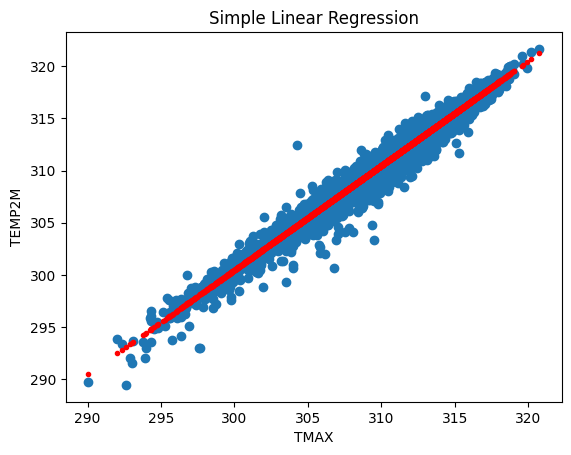

In [9]:
x = train["TMAX"].values
y = train["TEMP2M"].values

x_mean = np.mean(x)
y_mean = np.mean(y)

w1 = np.sum((x - x_mean) * (y - y_mean)) / np.sum((x - x_mean) ** 2)
w0 = y_mean - w1 * x_mean

actual = test["TEMP2M"].values
predicted1 = w0 + w1 * test["TMAX"].values

mae1 = np.mean(np.abs(actual - predicted1))
rmse1 = np.sqrt(np.mean((actual - predicted1) ** 2))
r21 = 1 - np.sum((actual - predicted1) ** 2) / np.sum((actual - actual.mean()) ** 2)

print("Simple Linear Regression")
print("Intercept:", w0)
print("Slope:", w1)
print("MAE:", mae1)
print("RMSE:", rmse1)
print("R2 Score:", r21)

plt.scatter(test["TMAX"], actual)
plt.plot(test["TMAX"], predicted1, "r.")
plt.xlabel("TMAX")
plt.ylabel("TEMP2M")
plt.title("Simple Linear Regression")
plt.show()

Multiple Linear Regression
Coefficients: [-4.18106191e+01  8.07554095e-01  2.19332360e-01  3.39000349e-04]
MAE: 0.5657659829496128
RMSE: 0.7994451558645475
R2 Score: 0.9717704927641752


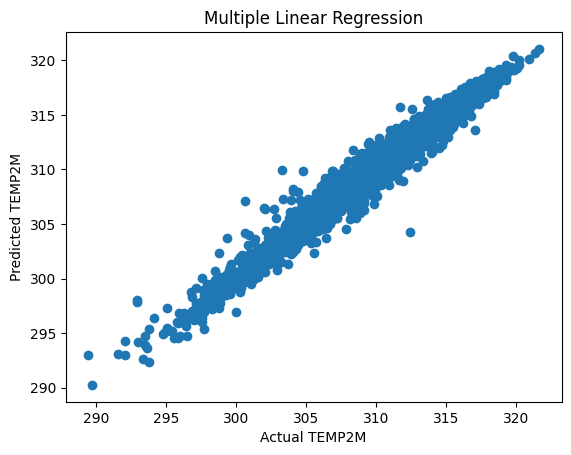

In [10]:
x_train = np.column_stack((
    np.ones(len(train)),
    train[["TMAX", "TMIN", "MSLP"]].values
))

x_test = np.column_stack((
    np.ones(len(test)),
    test[["TMAX", "TMIN", "MSLP"]].values
))

y_train = train["TEMP2M"].values
actual = test["TEMP2M"].values

b = np.linalg.pinv(x_train) @ y_train
predicted2 = x_test @ b

mae2 = np.mean(np.abs(actual - predicted2))
rmse2 = np.sqrt(np.mean((actual - predicted2) ** 2))
r22 = 1 - np.sum((actual - predicted2) ** 2) / np.sum((actual - actual.mean()) ** 2)

print("Multiple Linear Regression")
print("Coefficients:", b)
print("MAE:", mae2)
print("RMSE:", rmse2)
print("R2 Score:", r22)

plt.scatter(actual, predicted2)
plt.xlabel("Actual TEMP2M")
plt.ylabel("Predicted TEMP2M")
plt.title("Multiple Linear Regression")
plt.show()

In [11]:
mean_value = train["TEMP2M"].mean()
predicted_mean = np.full(len(test), mean_value)

mae_mean = np.mean(np.abs(actual - predicted_mean))
rmse_mean = np.sqrt(np.mean((actual - predicted_mean) ** 2))
r2_mean = 1 - np.sum((actual - predicted_mean) ** 2) / np.sum((actual - actual.mean()) ** 2)

print("Mean Imputation")
print("MAE:", mae_mean)
print("RMSE:", rmse_mean)
print("R2 Score:", r2_mean)

Mean Imputation
MAE: 3.76322651859617
RMSE: 4.758154736820121
R2 Score: -7.067530284121659e-06


In [12]:
comparison = pd.DataFrame({
    "Method": ["Mean Imputation", "Simple Linear Regression", "Multiple Linear Regression"],
    "MAE": [mae_mean, mae1, mae2],
    "RMSE": [rmse_mean, rmse1, rmse2],
    "R2 Score": [r2_mean, r21, r22]
})

print(comparison)

                       Method       MAE      RMSE  R2 Score
0             Mean Imputation  3.763227  4.758155 -0.000007
1    Simple Linear Regression  0.582133  0.814158  0.970722
2  Multiple Linear Regression  0.565766  0.799445  0.971770


In [13]:
new_df = df.copy()

valid_index = new_df.dropna(subset=["TMAX", "TMIN", "MSLP", "TEMP2M"]).index

np.random.seed(42)
missing_index = pd.Series(valid_index).sample(frac=0.1, random_state=42).values

actual_values = new_df.loc[missing_index, "TEMP2M"].copy()
new_df.loc[missing_index, "TEMP2M"] = np.nan

known = new_df.dropna(subset=["TMAX", "TMIN", "MSLP", "TEMP2M"])

x_known = np.column_stack((
    np.ones(len(known)),
    known[["TMAX", "TMIN", "MSLP"]].values
))

y_known = known["TEMP2M"].values
b = np.linalg.pinv(x_known) @ y_known

missing_rows = new_df.loc[missing_index]

x_missing = np.column_stack((
    np.ones(len(missing_rows)),
    missing_rows[["TMAX", "TMIN", "MSLP"]].values
))

predicted_values = x_missing @ b
new_df.loc[missing_index, "TEMP2M"] = predicted_values

print("Missing Values After Imputation:", new_df["TEMP2M"].isnull().sum())

Missing Values After Imputation: 0


In [14]:
mae_imputation = np.mean(np.abs(actual_values.values - predicted_values))

print("Imputation MAE:", mae_imputation)

result = pd.DataFrame({
    "Actual Value": actual_values.values,
    "Predicted Value": predicted_values
})

print(result.head(10))

new_df.to_csv("Rajasthan_Heatwave_Imputed.csv", index=False)
files.download("Rajasthan_Heatwave_Imputed.csv")

Imputation MAE: 0.561536426681958
   Actual Value  Predicted Value
0     310.94897       311.087418
1     310.34058       311.186415
2     302.46777       303.038995
3     312.15210       312.574404
4     316.86743       316.789864
5     306.71143       306.584880
6     302.49950       301.411262
7     312.50806       312.730649
8     315.97560       315.751602
9     311.08252       310.879483


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>